# Deuxieme partie - Terrain de jeu : consommation énergétique de 7 sites (2023-2024)

Ce notebook explore le dataset horaire `all_sites_combined.csv` (7 sites, 17 521 heures chacun).

**Comment l'utiliser**
- Exécutez les cellules de haut en bas (*Run All*), puis modifiez les **réglages** de la section 3 (site, dates, seuil) et relancez les cellules suivantes.
- Prérequis : `pip install pandas matplotlib ipykernel` dans le venv, et ce venv sélectionné comme *kernel*.
- Aucun fichier n'est écrit : tout reste dans le notebook.

## 1. Chargement

Les fichiers csv doivent se trouver dans le dossier /data

In [1]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# --- Affichage -------------------------------------------------------------
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Si le CSV n'est pas trouvé automatiquement, mettez son chemin ici -------
CSV_PATH = None   # exemple : r"C:\Users\...\ml\data\all_sites_combined.csv"


def trouver_fichier(nom):
    """Cherche un fichier par son nom dans le dossier courant, ses parents et leurs dossiers data/."""
    bases = [Path.cwd(), *list(Path.cwd().parents)[:3]]
    for base in bases:
        for sous in ("", "data", "ml/data"):
            dossier = base / sous
            if not dossier.is_dir():
                continue
            # recherche récursive uniquement dans les dossiers data/ (pas dans .venv)
            trouve = next(dossier.rglob(nom) if sous else dossier.glob(nom), None)
            if trouve:
                return trouve
    return None


chemin = Path(CSV_PATH) if CSV_PATH else trouver_fichier("all_sites_combined.csv")
if chemin is None or not chemin.exists():
    raise FileNotFoundError("all_sites_combined.csv introuvable : renseignez CSV_PATH ci-dessus.")

df = pd.read_csv(chemin, parse_dates=["timestamp"])
df = df.sort_values(["site_id", "timestamp"]).reset_index(drop=True)

print(f"Fichier : {chemin}")
print(f"{len(df):,} lignes, {df['site_id'].nunique()} sites, du {df['timestamp'].min()} au {df['timestamp'].max()}")
display(df.head())

Fichier : c:\Users\mboyadjian2024\Documents\GitHub\smart_energy_optimizer\ml\data\all_sites_combined.csv
122,647 lignes, 7 sites, du 2023-01-01 00:00:00 au 2024-12-31 00:00:00


,timestamp,site_id,site_type,site_name,consumption_kwh,consumption_euros,temperature_celsius,humidity_percent,solar_irradiance_wm2,hour,day_of_week,day_name,month,is_weekend,is_working_hours
0,2023-01-01 00:00:00,SITE001,office,Bureau Tertiaire,85.82,12.87,10.6,76.7,0.0,0,6,Sunday,1,1,0
1,2023-01-01 01:00:00,SITE001,office,Bureau Tertiaire,89.84,13.48,12.0,70.6,0.0,1,6,Sunday,1,1,0
2,2023-01-01 02:00:00,SITE001,office,Bureau Tertiaire,80.62,12.09,13.8,62.2,0.0,2,6,Sunday,1,1,0
3,2023-01-01 03:00:00,SITE001,office,Bureau Tertiaire,92.67,13.90,9.4,66.0,0.0,3,6,Sunday,1,1,0
4,2023-01-01 04:00:00,SITE001,office,Bureau Tertiaire,72.50,10.88,14.8,67.2,41.5,4,6,Sunday,1,1,0


Colonnes : `consumption_kwh` (consommation de l'heure), `consumption_euros` (coût), `temperature_celsius`, `humidity_percent`, `solar_irradiance_wm2` (ensoleillement), puis des colonnes calendaires (`hour`, `day_of_week`, `day_name`, `month`, `is_weekend`, `is_working_hours`).

In [2]:
# --- Contrôles de cohérence ---------------------------------------------------
# 1) Trous ou doublons dans le calendrier horaire
ctrl = {}
for site, g in df.groupby("site_id"):
    attendu = pd.date_range(g["timestamp"].min(), g["timestamp"].max(), freq="h")
    ctrl[site] = {"heures manquantes": len(attendu.difference(g["timestamp"])),
                  "doublons": int(g["timestamp"].duplicated().sum())}
print("Calendrier horaire :")
display(pd.DataFrame(ctrl).T)

# 2) Prix du kWh : constant ?
prix = (df["consumption_euros"] / df["consumption_kwh"]).replace([np.inf, -np.inf], np.nan)
print("Prix implicite (euros / kWh) :")
display(prix.describe().round(3).to_frame("prix"))

# 3) Ensoleillement la nuit (devrait être nul)
nuit = df[df["hour"].isin([0, 1, 2, 3, 22, 23])]
print(f"Heures de nuit avec ensoleillement > 0 : {(nuit['solar_irradiance_wm2'] > 0).mean():.2%}  "
      f"(max = {nuit['solar_irradiance_wm2'].max():.0f} W/m2)")

# 4) Consommations nulles ou négatives
print(f"Consommation = 0 : {(df['consumption_kwh'] == 0).sum()} heures | < 0 : {(df['consumption_kwh'] < 0).sum()} heures")

Calendrier horaire :


,heures manquantes,doublons
SITE001,0,0
SITE002,0,0
SITE003,0,0
SITE004,0,0
SITE005,0,0
SITE006,0,0
SITE007,0,0


Prix implicite (euros / kWh) :


,prix
count,118015.00
mean,0.15
std,0.00
min,0.15
25%,0.15
50%,0.15
75%,0.15
max,0.15


Heures de nuit avec ensoleillement > 0 : 48.39%  (max = 208 W/m2)
Consommation = 0 : 1792 heures | < 0 : 0 heures


## 3. Réglages (à modifier puis relancer les cellules suivantes)

In [3]:
DEBUT = "2023-01-01"      # période étudiée
FIN = "2024-12-31"
SEUIL_Z = 4.0             # sensibilité de la détection d'anomalies (section 7) : plus grand = moins d'alertes

## 5. Les rythmes de consommation (heure, jour, saison)

Compare les données de consommation selon le jour (si c'est en semaine ou en week end)

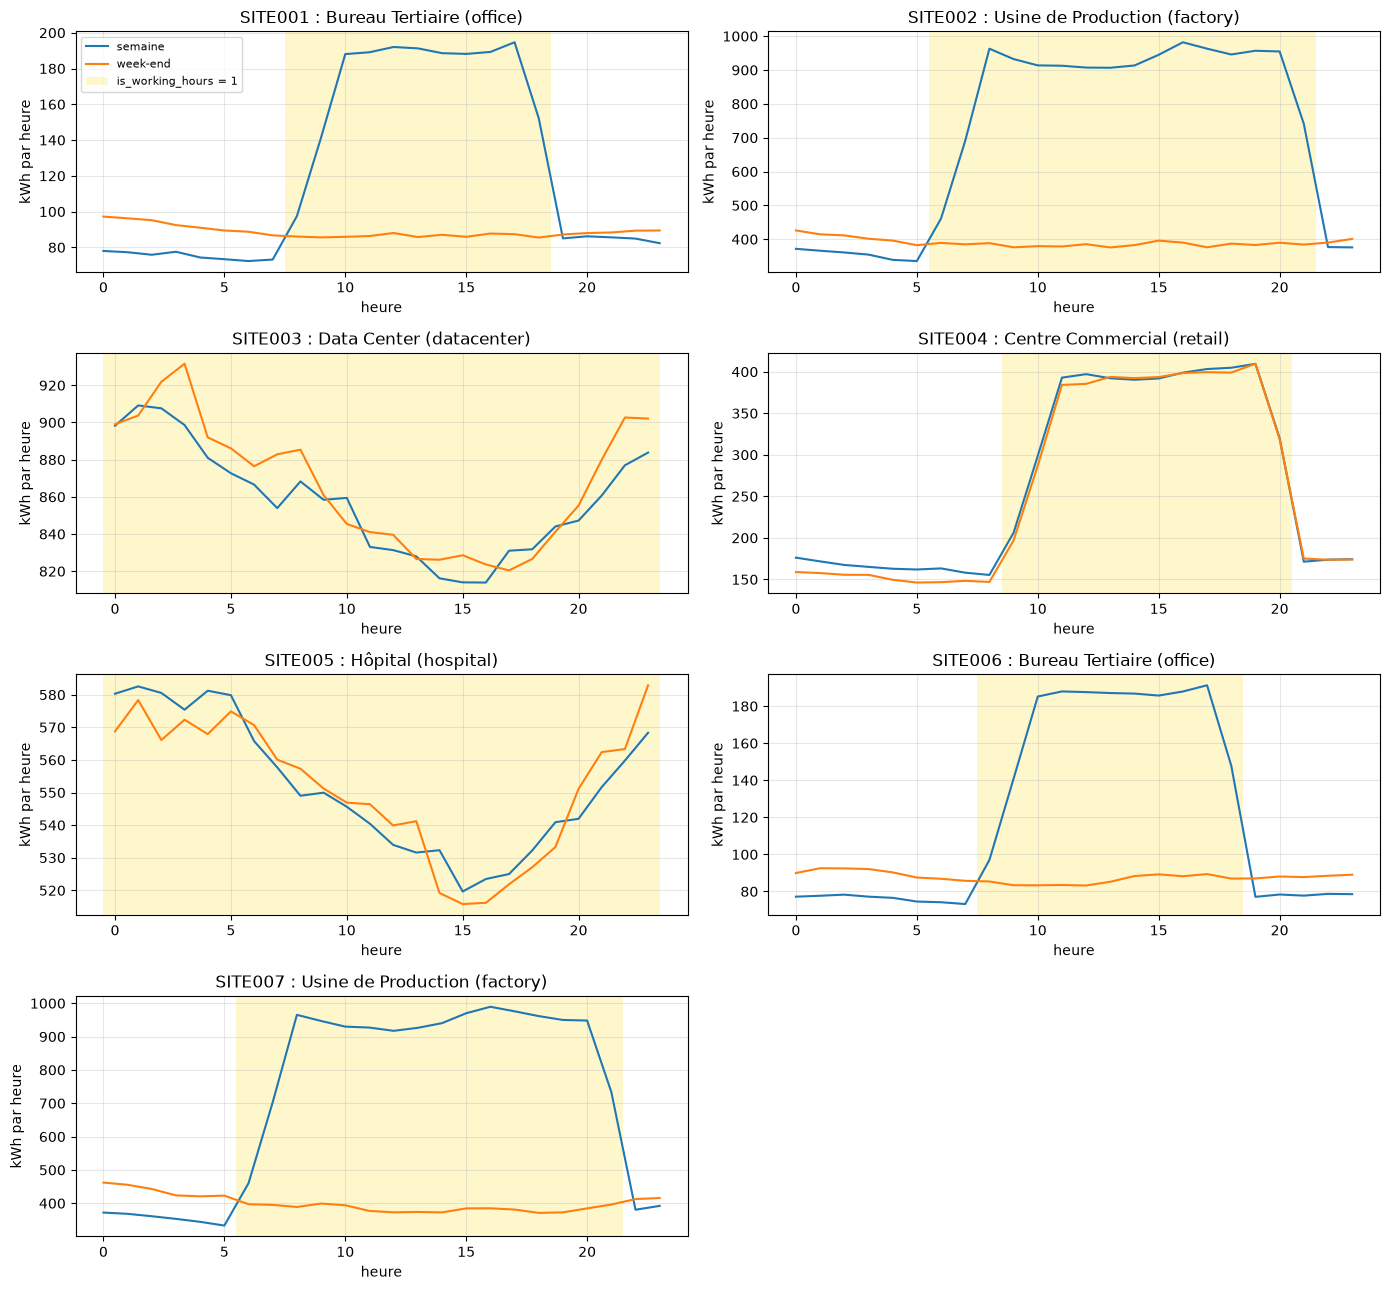

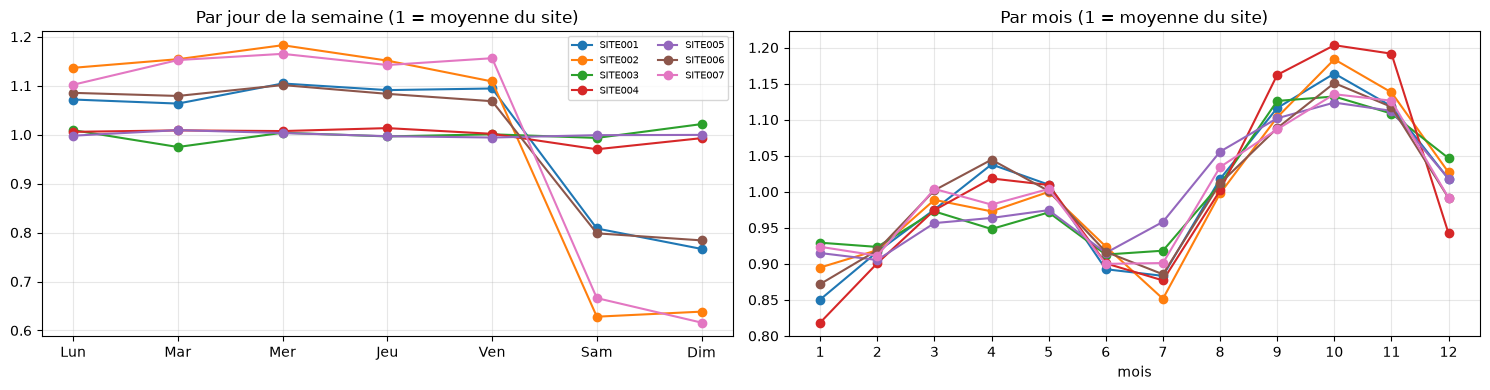

In [4]:
jours = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
jours_fr = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
fiche = df.groupby("site_id")[["site_name", "site_type"]].first()

# a) profil sur 24 h (semaine vs week-end), un graphique par site
#    zone dorée = heures où is_working_hours = 1 pour ce site
fig, axes = plt.subplots(4, 2, figsize=(14, 13))
for ax, (site, g) in zip(axes.flat, df.groupby("site_id")):
    profil = g.groupby(["is_weekend", "hour"])["consumption_kwh"].mean().unstack(0)
    profil.columns = ["semaine" if c == 0 else "week-end" for c in profil.columns]
    profil.plot(ax=ax, legend=False)

    h_travail = sorted(g.loc[g["is_working_hours"] == 1, "hour"].unique())
    for h in h_travail:
        ax.axvspan(h - 0.5, h + 0.5, color="gold", alpha=0.2, lw=0,
                   label="is_working_hours = 1" if h == h_travail[0] else None)
    ax.set(title=f"{site} : {fiche.loc[site, 'site_name']} ({fiche.loc[site, 'site_type']})",
           xlabel="heure", ylabel="kWh par heure")
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")          # 8e case inutilisée
plt.tight_layout()
plt.show()

# b) et c) jour de la semaine et mois, tous les sites ensemble
#    (normalisés : 1 = consommation moyenne du site, pour comparer des sites de tailles différentes)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

par_jour = df.groupby(["day_name", "site_id"])["consumption_kwh"].mean().unstack().reindex(jours)
(par_jour / par_jour.mean()).plot(ax=axes[0], marker="o", title="Par jour de la semaine (1 = moyenne du site)")
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(jours_fr)
axes[0].set_xlabel("")
axes[0].legend(ncol=2, fontsize=7)

par_mois = df.groupby(["month", "site_id"])["consumption_kwh"].mean().unstack()
(par_mois / par_mois.mean()).plot(ax=axes[1], marker="o", title="Par mois (1 = moyenne du site)", legend=False)
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("mois")

plt.tight_layout()
plt.show()

Le graphique du dessus permet de comparer la consommation de chaque site à ses propres habitudes. On compare les rythmes de sites de tailles différentes pour voir quels sites semble avoir la meme habitude.

Ça ne montre pas quel site consomme le plus

### Vérifie les possibles incohérence entre la date et le jour indiqué 

In [5]:
# Contrôle de cohérence des dates : chaque ligne est comparée à un calcul indépendant (formule de Zeller)
JOURS_ZELLER = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
JOURS_LUNDI0 = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def jour_zeller(annee, mois, jour):
    """Jour de la semaine d'une date (calendrier grégorien), sans datetime ni pandas."""
    if mois < 3:
        mois += 12
        annee -= 1
    K, J = annee % 100, annee // 100
    h = (jour + (13 * (mois + 1)) // 5 + K + K // 4 + J // 4 + 5 * J) % 7
    return JOURS_ZELLER[h]


def controle_dates(data):
    """Renvoie (résumé des tests, lignes incohérentes) pour un tableau avec les colonnes calendaires."""
    t = data["timestamp"]
    # jour de la semaine calculé une seule fois par date distincte, puis recopié sur chaque ligne
    jour_date = {d: jour_zeller(d.year, d.month, d.day) for d in t.dt.date.unique()}
    zeller = t.dt.date.map(jour_date)

    tests = pd.DataFrame({
        "day_name différent de Zeller": data["day_name"] != zeller,
        "day_of_week différent de Zeller": data["day_of_week"] != zeller.map(JOURS_LUNDI0.index),
        "is_weekend incohérent": data["is_weekend"] != zeller.isin(["Saturday", "Sunday"]).astype(int),
        "month différent du timestamp": data["month"] != t.dt.month,
        "hour différente du timestamp": data["hour"] != t.dt.hour,
        "timestamp pas à l'heure pile": (t.dt.minute != 0) | (t.dt.second != 0),
        "timestamp manquant": t.isna(),
    })
    resume = tests.sum().rename("nb de lignes").to_frame()

    # lignes concernées, avec ce qui ne va pas
    cols = ["timestamp", "site_id", "day_name", "day_of_week", "is_weekend", "month", "hour"]
    masque = tests.any(axis=1)
    mauvaises = data.loc[masque, cols].copy()
    mauvaises["jour attendu (Zeller)"] = zeller[masque]
    sous = tests[masque]
    mauvaises["problèmes"] = [", ".join(sous.columns[ligne]) for ligne in sous.to_numpy()]
    return resume, mauvaises


resume, mauvaises = controle_dates(df)
print(f"{len(df):,} lignes contrôlées")
display(resume)
print(f"Lignes incohérentes : {len(mauvaises)}")
if len(mauvaises):
    display(mauvaises.head(20))

# --- Le contrôle est-il fiable ? On injecte volontairement 3 erreurs dans une copie ---
test = df.copy()
test.loc[10, "day_name"] = "Monday"          # le 1er janvier 2023 deviendrait un lundi
test.loc[500, "is_weekend"] = 1 - test.loc[500, "is_weekend"]
test.loc[900, "hour"] = (test.loc[900, "hour"] + 1) % 24
_, detectees = controle_dates(test)
print(f"\nTest du contrôle : 3 erreurs injectées, {len(detectees)} lignes détectées")
display(detectees[["timestamp", "site_id", "problèmes"]])

# --- Calendrier : trous, doublons, jours incomplets, pour chaque site ---
lignes = []
for site, g in df.groupby("site_id"):
    attendu = pd.date_range(g["timestamp"].min(), g["timestamp"].max(), freq="h")
    par_jour = g.groupby(g["timestamp"].dt.date).size()
    incomplets = par_jour[par_jour != 24]
    lignes.append({
        "site": site,
        "début": g["timestamp"].min(),
        "fin": g["timestamp"].max(),
        "heures manquantes": len(attendu.difference(g["timestamp"])),
        "doublons": int(g["timestamp"].duplicated().sum()),
        "jours avec moins ou plus de 24 lignes": ", ".join(f"{d} ({n})" for d, n in incomplets.items()) or "aucun",
    })
display(pd.DataFrame(lignes).set_index("site"))

# 29 février 2024 : bien présent (année bissextile) ?
bissextile = df[(df["timestamp"] >= "2024-02-29") & (df["timestamp"] < "2024-03-01")]
print(f"Lignes le 29/02/2024 : {len(bissextile)} (attendu : 24 par site x {df['site_id'].nunique()} sites = {24 * df['site_id'].nunique()})")

122,647 lignes contrôlées


,nb de lignes
day_name différent de Zeller,0
day_of_week différent de Zeller,0
is_weekend incohérent,0
month différent du timestamp,0
hour différente du timestamp,0
timestamp pas à l'heure pile,0
timestamp manquant,0


Lignes incohérentes : 0

Test du contrôle : 3 erreurs injectées, 3 lignes détectées


,timestamp,site_id,problèmes
10,2023-01-01 10:00:00,SITE001,day_name différent de Zeller
500,2023-01-21 20:00:00,SITE001,is_weekend incohérent
900,2023-02-07 12:00:00,SITE001,hour différente du timestamp


,début,fin,heures manquantes,doublons,jours avec moins ou plus de 24 lignes
site,,,,,
SITE001,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE002,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE003,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE004,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE005,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE006,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE007,2023-01-01,2024-12-31,0,0,2024-12-31 (1)


Lignes le 29/02/2024 : 168 (attendu : 24 par site x 7 sites = 168)


## 6. Comparer les sites

,type,nom,moyenne_kwh,mediane_kwh,max_kwh,total_GWh,cout_k_euros,pct_nuls,max / moyenne
site_id,,,,,,,,,
SITE001,office,Bureau Tertiaire,112.74,86.74,1006.26,1.93,290.12,2.35,8.9
SITE002,factory,Usine de Production,616.65,479.06,3225.29,10.55,1588.31,2.32,5.2
SITE003,datacenter,Data Center,860.31,826.50,2734.88,14.72,2215.07,2.32,3.2
SITE004,retail,Centre Commercial,265.03,209.32,1854.34,4.54,682.15,2.31,7.0
SITE005,hospital,Hôpital,551.86,528.79,2471.61,9.44,1420.87,2.33,4.5
SITE006,office,Bureau Tertiaire,110.73,86.52,595.84,1.90,285.23,2.27,5.4
SITE007,factory,Usine de Production,623.99,474.76,4599.76,10.68,1607.42,2.30,7.4


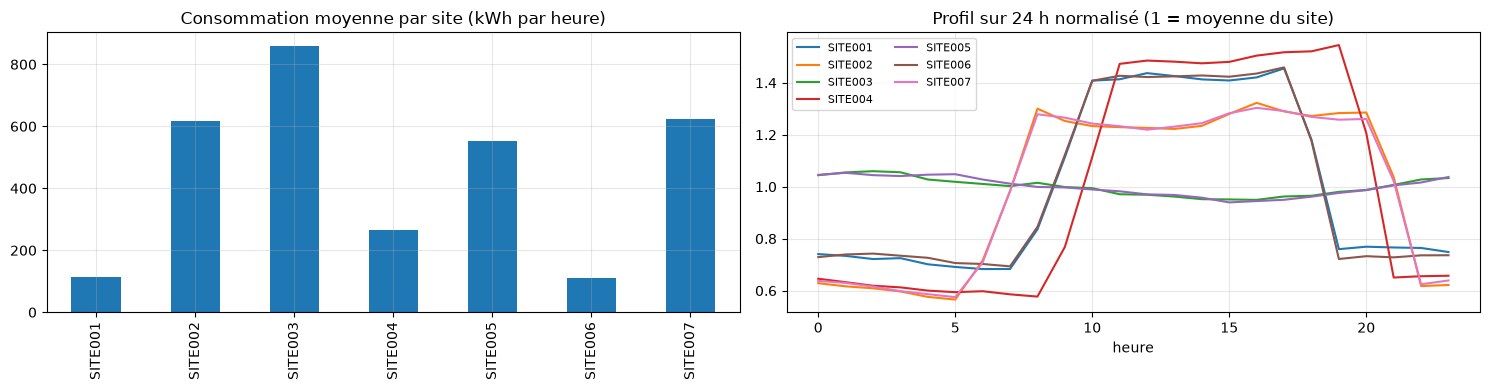

In [6]:
resume = df.groupby("site_id").agg(
    type=("site_type", "first"),
    nom=("site_name", "first"),
    moyenne_kwh=("consumption_kwh", "mean"),
    mediane_kwh=("consumption_kwh", "median"),
    max_kwh=("consumption_kwh", "max"),
    total_GWh=("consumption_kwh", lambda x: x.sum() / 1e6),
    cout_k_euros=("consumption_euros", lambda x: x.sum() / 1e3),
    pct_nuls=("consumption_kwh", lambda x: x.isna().mean() * 100),
).round(2)
resume["max / moyenne"] = (resume["max_kwh"] / resume["moyenne_kwh"]).round(1)
display(resume)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
resume["moyenne_kwh"].plot.bar(ax=axes[0], title="Consommation moyenne par site (kWh par heure)")
axes[0].set(xlabel="")

# Forme du profil sur 24 h, indépendamment de la taille du site (1 = moyenne du site)
prof = df.groupby(["site_id", "hour"])["consumption_kwh"].mean().unstack(0)
(prof / prof.mean()).plot(ax=axes[1], title="Profil sur 24 h normalisé (1 = moyenne du site)")
axes[1].set(xlabel="heure")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

# 7 Comparatif des données avec température

In [7]:
# --- Météo et consommation : corrélations (CSV, 7 sites) ----------------------
habituel = df.groupby(["site_id", "day_of_week", "hour"])["consumption_kwh"].transform("mean")
c = df.assign(
    conso_corrigee=df["consumption_kwh"] / habituel,                 # 1 = consommation habituelle
    ecart_confort=(df["temperature_celsius"] - 19).abs(),            # distance à 19 °C (forme en U)
).dropna(subset=["consumption_kwh", "temperature_celsius"])

# Heures "normales" : on écarte pannes (conso ≈ 0) et pics/plateaux (> 1,4 × l'habituel)
normales = c[(c["conso_corrigee"] > 0.6) & (c["conso_corrigee"] < 1.4)]

par_site = lambda d, f: d.groupby("site_id").apply(f)
fiche = df.groupby("site_id")["site_type"].first()
display(pd.DataFrame({
    "type": fiche,
    "température, brute": par_site(c, lambda g: g["consumption_kwh"].corr(g["temperature_celsius"])),
    "température, corrigée du rythme": par_site(c, lambda g: g["conso_corrigee"].corr(g["temperature_celsius"])),
    "écart à 19 °C, toutes heures": par_site(c, lambda g: g["conso_corrigee"].corr(g["ecart_confort"])),
    "écart à 19 °C, heures normales": par_site(normales, lambda g: g["conso_corrigee"].corr(g["ecart_confort"])),
    "humidité (Spearman)": par_site(c, lambda g: g["conso_corrigee"].corr(g["humidity_percent"], method="spearman")),
    "ensoleillement (Spearman)": par_site(c, lambda g: g["conso_corrigee"].corr(g["solar_irradiance_wm2"], method="spearman")),
}).round(2))

,type,"température, brute","température, corrigée du rythme","écart à 19 °C, toutes heures","écart à 19 °C, heures normales",humidité (Spearman),ensoleillement (Spearman)
site_id,,,,,,,
SITE001,office,0.12,-0.15,0.26,0.63,-0.30,0.10
SITE002,factory,0.08,-0.16,0.26,0.45,-0.23,0.11
SITE003,datacenter,-0.28,-0.23,0.37,0.71,-0.40,0.01
SITE004,retail,0.09,-0.17,0.28,0.54,-0.27,0.16
SITE005,hospital,-0.26,-0.21,0.34,0.70,-0.42,0.02
SITE006,office,0.15,-0.16,0.30,0.67,-0.33,0.09
SITE007,factory,0.09,-0.14,0.24,0.44,-0.23,0.14


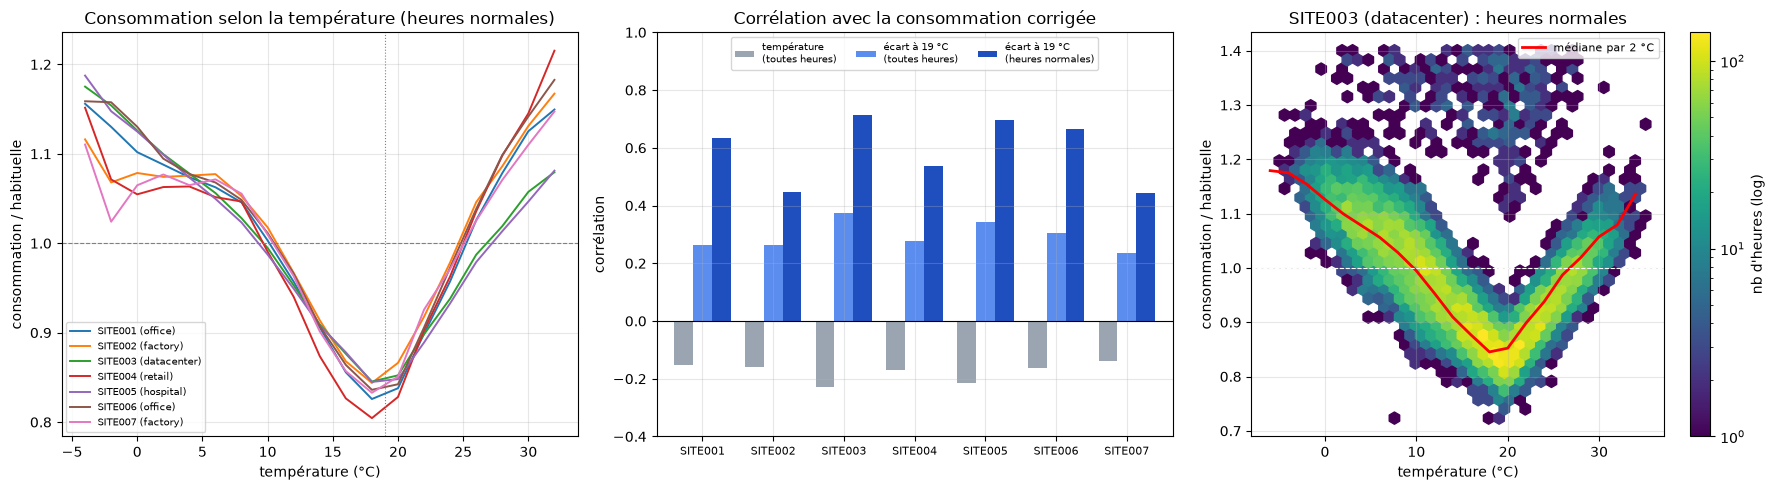

In [9]:
# --- Météo et consommation : les graphiques (CSV, 7 sites) --------------------
habituel = df.groupby(["site_id", "day_of_week", "hour"])["consumption_kwh"].transform("mean")
c = df.assign(
    conso_corrigee=df["consumption_kwh"] / habituel,
    ecart_confort=(df["temperature_celsius"] - 19).abs(),
).dropna(subset=["consumption_kwh", "temperature_celsius"])
normales = c[(c["conso_corrigee"] > 0.6) & (c["conso_corrigee"] < 1.4)]      # sans pannes ni pics
fiche = df.groupby("site_id")["site_type"].first()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. La courbe en U : médiane par tranche de 2 °C, heures normales, 7 sites
ax = axes[0]
for site, g in normales.groupby("site_id"):
    t = g.groupby((g["temperature_celsius"] // 2) * 2)["conso_corrigee"].agg(["median", "size"])
    t = t[t["size"] >= 30]
    ax.plot(t.index, t["median"], lw=1.4, label=f"{site} ({fiche[site]})")
ax.axhline(1, color="gray", ls="--", lw=0.8)
ax.axvline(19, color="gray", ls=":", lw=0.8)
ax.set(title="Consommation selon la température (heures normales)",
       xlabel="température (°C)", ylabel="consommation / habituelle")
ax.legend(fontsize=7)

# 2. Corrélation : la droite (température) contre le U (écart à 19 °C)
ax = axes[1]
res = pd.DataFrame({
    "température\n(toutes heures)": c.groupby("site_id").apply(lambda g: g["conso_corrigee"].corr(g["temperature_celsius"])),
    "écart à 19 °C\n(toutes heures)": c.groupby("site_id").apply(lambda g: g["conso_corrigee"].corr(g["ecart_confort"])),
    "écart à 19 °C\n(heures normales)": normales.groupby("site_id").apply(lambda g: g["conso_corrigee"].corr(g["ecart_confort"])),
})
res.plot.bar(ax=ax, width=0.8, color=["#9aa5b1", "#5b8def", "#1f4fbf"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Corrélation avec la consommation corrigée", xlabel="", ylabel="corrélation", ylim=(-0.4, 1.0))
ax.tick_params(axis="x", rotation=0, labelsize=8)
ax.legend(fontsize=7, ncol=3, loc="upper center")

# 3. Même chose en nuage de points pour un site (le U se voit directement)
ax = axes[2]
g = normales[normales["site_id"] == "SITE003"]
hb = ax.hexbin(g["temperature_celsius"], g["conso_corrigee"], gridsize=35, cmap="viridis", mincnt=1, bins="log")
tr = g.groupby((g["temperature_celsius"] // 2) * 2)["conso_corrigee"].median()
ax.plot(tr.index, tr.values, color="red", lw=2, label="médiane par 2 °C")
ax.axhline(1, color="white", ls="--", lw=0.8)
ax.set(title=f"SITE003 ({fiche['SITE003']}) : heures normales",
       xlabel="température (°C)", ylabel="consommation / habituelle")
ax.legend(fontsize=8)
fig.colorbar(hb, ax=ax, label="nb d'heures (log)")

plt.tight_layout(); plt.show()

Les sites consomment moins à 19°C, quand il fait ni trop chaud ni trop froid et consommes plus sur les températures pour chaudes et froides (hypothèses : pour climatiser ou chauffer les pieces)

Plus on s'éloigne de 19°C, plus la consommation monte --> il pourrait être intéressant d'inclure cette variable dans le modèle, en prenant en compte une API météo pour obtenir les prévisions de température dans les prochaines heures

# 8 Comparatif avec les données API

In [10]:
# --- Corrélations sur les données de l'API (/readings) ------------------------
import os, httpx
from pathlib import Path
from dotenv import load_dotenv

# .env : on remonte les dossiers parents jusqu'à le trouver
for dossier in [Path.cwd(), *Path.cwd().parents]:
    if (dossier / ".env").exists():
        load_dotenv(dossier / ".env"); break

BASE = os.getenv("ENERVISION_API_URL", "https://api-mock.charlieandre.fr").rstrip("/")
auth = httpx.BasicAuth(os.getenv("ENERVISION_API_USERNAME"), os.getenv("ENERVISION_API_PASSWORD"))

lignes = []
with httpx.Client(base_url=BASE, auth=auth, timeout=30) as api:
    for site in [f"SITE{i:03d}" for i in range(1, 8)]:
        r = api.get("/api/v1/readings", params={"site_id": site, "limit": 1000})
        r.raise_for_status()
        lignes += r.json() if isinstance(r.json(), list) else r.json().get("items", r.json().get("data", []))

api_df = pd.DataFrame(lignes)
print(api_df.shape); print(list(api_df.columns))      # <- vérifiez les noms ici
display(api_df.head(3))

(7000, 12)
['timestamp', 'site_id', 'site_type', 'consumption_kw', 'consumption_kwh', 'voltage_v', 'current_a', 'power_factor', 'temperature_celsius', 'humidity_percent', 'null_reasons', 'data_quality']


,timestamp,site_id,site_type,consumption_kw,consumption_kwh,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent,null_reasons,data_quality
0,2026-10-22T10:58:42.243579Z,SITE001,office,162.44,162.44,401.1,246.13,0.905,9.0,36.5,[],good
1,2026-10-22T11:00:08.643579Z,SITE001,office,177.29,177.29,399.5,269.73,0.862,11.1,33.9,[],good
2,2026-10-22T11:01:35.043579Z,SITE001,office,160.67,160.67,404.7,241.26,0.959,12.7,39.1,[],good


In [11]:
# --- Différence de schéma : CSV (df) vs API (api_df) --------------------------
import difflib

def fiche(d, nom):
    """Une ligne par colonne : type, % de nuls, exemple, nombre de valeurs distinctes."""
    lignes = []
    for col in d.columns:
        s = d[col]
        exemple = s.dropna().iloc[0] if s.notna().any() else None
        lignes.append({
            "colonne": col,
            "type": type(exemple).__name__ if exemple is not None else "vide",  # list / dict = champ imbriqué
            "dtype pandas": str(s.dtype),
            "% nuls": round(s.isna().mean() * 100, 1),
            "exemple": str(exemple)[:40],
        })
    return pd.DataFrame(lignes).set_index("colonne").add_suffix(f" ({nom})")

csv_cols, api_cols = set(df.columns), set(api_df.columns)

# 1. Colonnes communes / seulement d'un côté
print("Colonnes communes      :", sorted(csv_cols & api_cols))
print("Seulement dans le CSV  :", sorted(csv_cols - api_cols))
print("Seulement dans l'API   :", sorted(api_cols - csv_cols))

# 2. Pour chaque colonne propre à un côté, la colonne la plus ressemblante de l'autre (rename probable)
print("\nCorrespondances probables (renommages) :")
for col in sorted(csv_cols - api_cols):
    proche = difflib.get_close_matches(col, list(api_cols - csv_cols), n=1, cutoff=0.5)
    print(f"  CSV {col:25s} -> API {proche[0] if proche else '(aucune)'}")

# 3. Fiche détaillée des deux côtés, côte à côte
display(fiche(df, "CSV").join(fiche(api_df, "API"), how="outer"))

Colonnes communes      : ['consumption_kwh', 'humidity_percent', 'site_id', 'site_type', 'temperature_celsius', 'timestamp']
Seulement dans le CSV  : ['consumption_euros', 'day_name', 'day_of_week', 'hour', 'is_weekend', 'is_working_hours', 'month', 'site_name', 'solar_irradiance_wm2']
Seulement dans l'API   : ['consumption_kw', 'current_a', 'data_quality', 'null_reasons', 'power_factor', 'voltage_v']

Correspondances probables (renommages) :
  CSV consumption_euros         -> API consumption_kw
  CSV day_name                  -> API (aucune)
  CSV day_of_week               -> API (aucune)
  CSV hour                      -> API (aucune)
  CSV is_weekend                -> API (aucune)
  CSV is_working_hours          -> API (aucune)
  CSV month                     -> API (aucune)
  CSV site_name                 -> API (aucune)
  CSV solar_irradiance_wm2      -> API (aucune)


,type (CSV),dtype pandas (CSV),% nuls (CSV),exemple (CSV),type (API),dtype pandas (API),% nuls (API),exemple (API)
colonne,,,,,,,,
consumption_euros,float64,float64,2.0,12.87,NaN,NaN,NaN,NaN
consumption_kw,NaN,NaN,NaN,NaN,float64,float64,5.8,162.44
consumption_kwh,float64,float64,2.3,85.82,float64,float64,5.8,162.44
current_a,NaN,NaN,NaN,NaN,float64,float64,6.0,246.13
data_quality,NaN,NaN,NaN,NaN,str,str,0.0,good
day_name,str,str,0.0,Sunday,NaN,NaN,NaN,NaN
day_of_week,int64,int64,0.0,6,NaN,NaN,NaN,NaN
hour,int64,int64,0.0,0,NaN,NaN,NaN,NaN
humidity_percent,float64,float64,2.8,76.7,float64,float64,7.9,36.5


In [12]:
# --- Mêmes colonnes : les valeurs sont-elles du même ordre de grandeur ? ------
communes = [c for c in df.columns if c in api_df.columns
            and pd.api.types.is_numeric_dtype(df[c]) and pd.api.types.is_numeric_dtype(api_df[c])]
comparaison = pd.DataFrame({
    "min CSV": df[communes].min(), "min API": api_df[communes].min(),
    "moy CSV": df[communes].mean(), "moy API": api_df[communes].mean(),
    "max CSV": df[communes].max(), "max API": api_df[communes].max(),
})
display(comparaison.round(2))

# Sites et période couverts
print("Sites CSV :", sorted(df["site_id"].unique()))
print("Sites API :", sorted(api_df["site_id"].unique()))
t_api = pd.to_datetime(api_df["timestamp"], format="ISO8601", utc=True).dt.tz_localize(None)
print(f"Période CSV : {df['timestamp'].min()} -> {df['timestamp'].max()}")
print(f"Période API : {t_api.min()} -> {t_api.max()}")
print("Pas de temps API (médiane) :", t_api.sort_values().diff().median())

# Valeurs des colonnes catégorielles propres à l'API (data_quality, null_reasons...)
for col in sorted(api_cols - csv_cols):
    s = api_df[col]
    if s.map(lambda x: isinstance(x, (list, dict))).any():
        print(f"{col}: champ imbriqué, exemple {s.dropna().iloc[0]}")
    elif s.nunique() <= 10:
        print(f"{col}: {s.value_counts(dropna=False).to_dict()}")

,min CSV,min API,moy CSV,moy API,max CSV,max API
consumption_kwh,0.0,47.69,448.74,415.89,4599.76,1075.64
temperature_celsius,-7.1,-6.10,14.97,4.99,36.30,17.50
humidity_percent,30.0,30.00,59.89,42.57,95.00,60.90


Sites CSV : ['SITE001', 'SITE002', 'SITE003', 'SITE004', 'SITE005', 'SITE006', 'SITE007']
Sites API : ['SITE001', 'SITE002', 'SITE003', 'SITE004', 'SITE005', 'SITE006', 'SITE007']
Période CSV : 2023-01-01 00:00:00 -> 2024-12-31 00:00:00
Période API : 2026-10-22 10:58:42.243579 -> 2026-10-23 10:57:16.639675
Pas de temps API (médiane) : 0 days 00:00:00.125883
data_quality: {'good': 5507, 'partial': 1274, 'critical': 126, 'degraded': 93}
null_reasons: champ imbriqué, exemple []


## Conclusion

Les schémas présentes des différences importantes.
La période CSV ne concernent que les années 2023 à 2024 alors que l'api reading ne semble pas avoir de limite dans la date de début de la période